<a href="https://colab.research.google.com/github/twyeh/university-physics/blob/main/newtons_cradle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

In [3]:
!pip install pymunk
import pymunk
from pymunk.vec2d import Vec2d
import pymunk.matplotlib_util

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 10.1 MB/s  0:00:00


In [4]:
def setup_space():
    space = pymunk.Space()
    space.gravity = 0,-9820
    space.damping = 0.99
    return space


In [5]:
def setup_balls(space):
    width = 600
    height = 600
    for x in range(-100,150,50):
        x += width / 2
        offset_y = height/2
        mass = 10
        radius = 25
        moment = pymunk.moment_for_circle(mass, 0, radius, (0,0))
        body = pymunk.Body(mass, moment)
        body.position = x, -125+offset_y
        body.start_position = Vec2d(*body.position)
        shape = pymunk.Circle(body, radius)
        shape.elasticity = 0.9999999
        space.add(body, shape)
        pj = pymunk.PinJoint(space.static_body, body, (x, 125+offset_y), (0,0))
        space.add(pj)

We reuse the debug drawing code from pymunk.matplotlib_util. Currently this is not optimal since it doesnt reuse the artists added to the axes, instead we have to clear the axes each frame and redraw it which is quite expensive. Hopefully a future version of pymunk will support a better way to do it.

For now if you want to draw a more complicated scene I recommend that you use pymunk.matplotlib_util as inspiration but write the drawing code yourself to better optimize the animation.

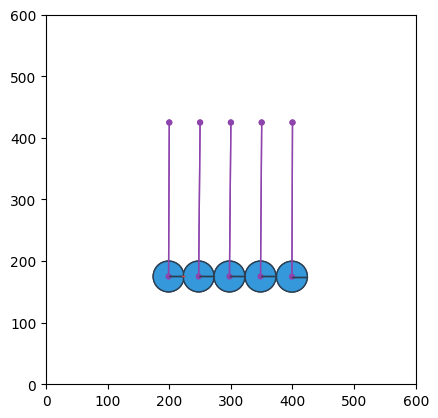

In [9]:
import warnings
# 精確過濾 matplotlib_util.DrawOptions 的過期警告
warnings.filterwarnings("ignore", category=DeprecationWarning, message=".*matplotlib_util.DrawOptions.*")

fig = plt.figure()
ax = plt.axes(xlim=(0, 600), ylim=(0, 600))
ax.set_aspect("equal")

space = setup_space()
setup_balls(space)

o = pymunk.matplotlib_util.DrawOptions(ax)

# Apply impulse to the first ball to start the Newton's cradle swing
list(space.shapes)[1].body.apply_impulse_at_local_point((-12000, 0))

def init():
    space.debug_draw(o)
    return []

def animate(dt):
    # Run the physics simulation step
    for x in range(10):
        space.step(1/50/10/2)

    # Clear and restore limits/aspect ratio
    ax.clear()
    ax.set_xlim(0, 600)
    ax.set_ylim(0, 600)
    ax.set_aspect("equal")

    # Redraw
    space.debug_draw(o)
    return []

frames = 105
anim = animation.FuncAnimation(fig, animate, init_func=init,
                               frames=frames, interval=20, blit=False)

HTML(anim.to_html5_video())

```markdown
### 手動繪製與優化動畫效能 (Matplotlib Artists Update)
為了避免每幀呼叫 `ax.clear()` 造成的效能損耗，我們：
1. 在 `init()` 建立好所有的 `Circle`（球）與 `Line2D`（線）並加入 `ax`。
2. 在 `animate()` 中只去更新每個物件的中心位置（`set_center`）與線段端點（`set_data`）。
```

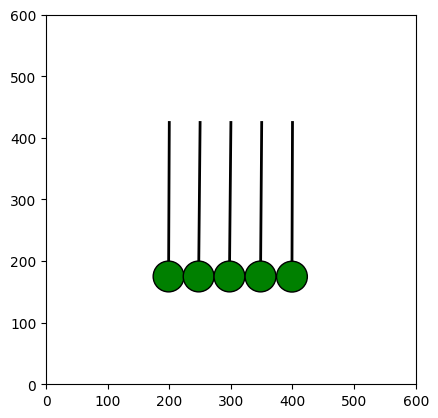

In [11]:
import matplotlib.patches as patches

fig, ax = plt.subplots()
ax.set_xlim(0, 600)
ax.set_ylim(0, 600)
ax.set_aspect("equal")

# 重新初始化物理空間
space = setup_space()
setup_balls(space)

# 施加初始衝量
list(space.shapes)[1].body.apply_impulse_at_local_point((-12000, 0))

# 準備儲存 matplotlib artists 的列表
ball_artists = []
line_artists = []

# 取得空間中的所有形狀與關節資料
balls = [shape for shape in space.shapes if isinstance(shape, pymunk.Circle)]
joints = [constraint for constraint in space.constraints if isinstance(constraint, pymunk.PinJoint)]

# 1. 在初始化時，預先繪製好圖形物件並固定加入到軸（ax）中
for ball in balls:
    # 建立圓形
    circle = patches.Circle((ball.body.position.x, ball.body.position.y),
                           radius=ball.radius, fc='g', ec='black', zorder=3)
    ax.add_patch(circle)
    ball_artists.append(circle)

for joint in joints:
    # 取得關節連接點
    # PinJoint 連接了 static_body (anchor a) 與 ball.body (anchor b)
    pos_a = joint.a.position + joint.anchor_a
    pos_b = joint.b.position + joint.anchor_b

    # 繪製線段
    line, = ax.plot([pos_a.x, pos_b.x], [pos_a.y, pos_b.y], color='black', lw=2, zorder=2)
    line_artists.append(line)

def init_opt():
    # 這裡只回傳需要更新的 artists（若 blit=True 需要，此處我們回傳全部）
    return ball_artists + line_artists

def animate_opt(dt):
    # 執行物理引擎運算
    for x in range(10):
        space.step(1/50/10/2)

    # 2. 手動更新既有物件的座標，不再重新繪製/不呼叫 ax.clear()
    for ball, circle in zip(balls, ball_artists):
        circle.set_center((ball.body.position.x, ball.body.position.y))

    for joint, line in zip(joints, line_artists):
        pos_a = joint.a.position + joint.anchor_a
        pos_b = joint.b.position + joint.anchor_b
        line.set_data([pos_a.x, pos_b.x], [pos_a.y, pos_b.y])

    return ball_artists + line_artists

frames = 105
# 將 interval 縮短至 10ms，使播放速度更快、更流暢
anim_opt = animation.FuncAnimation(fig, animate_opt, init_func=init_opt,
                                   frames=frames, interval=10, blit=True)

HTML(anim_opt.to_html5_video())

### 視覺美化版本 (加入背景色與網格線)
我們在此版本中對 Matplotlib 進行以下美化設定：
* 設定繪圖區背景色（`facecolor`）與邊框。
* 加入半透明的灰色虛線網格（`grid`）。
* 將球體顏色改為科技質感的藍色，提升視覺效果。

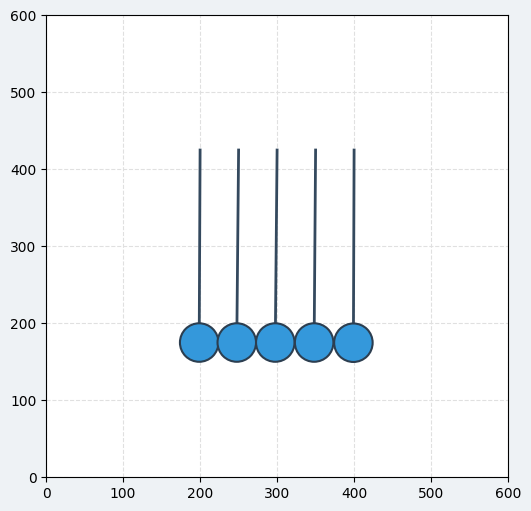

In [12]:
import matplotlib.patches as patches

# 建立具有美化背景顏色的圖表
fig, ax = plt.subplots(figsize=(6, 6))
fig.patch.set_facecolor('#eef2f5')      # 整個畫布的外圍背景色
ax.set_facecolor('#ffffff')             # 物理模擬區域的背景色 (純白)

# 設定網格線
ax.grid(True, linestyle='--', color='#e0e0e0', linewidth=0.8, zorder=1)

ax.set_xlim(0, 600)
ax.set_ylim(0, 600)
ax.set_aspect("equal")

# 重新初始化物理空間
space = setup_space()
setup_balls(space)

# 施加初始衝量
list(space.shapes)[1].body.apply_impulse_at_local_point((-12000, 0))

# 準備儲存 matplotlib artists 的列表
ball_artists = []
line_artists = []

# 取得空間中的所有形狀與關節資料
balls = [shape for shape in space.shapes if isinstance(shape, pymunk.Circle)]
joints = [constraint for constraint in space.constraints if isinstance(constraint, pymunk.PinJoint)]

# 1. 預先繪製好美化後的圖形物件 (zorder 確保層級正確：網格1 -> 線段2 -> 球體3)
for ball in balls:
    # 建立亮藍色的球體，並加上深藍色邊框
    circle = patches.Circle((ball.body.position.x, ball.body.position.y),
                           radius=ball.radius, fc='#3498db', ec='#2c3e50', lw=1.5, zorder=3)
    ax.add_patch(circle)
    ball_artists.append(circle)

for joint in joints:
    pos_a = joint.a.position + joint.anchor_a
    pos_b = joint.b.position + joint.anchor_b

    # 繪製粗細適中的連接線段
    line, = ax.plot([pos_a.x, pos_b.x], [pos_a.y, pos_b.y], color='#34495e', lw=2, zorder=2)
    line_artists.append(line)

def init_opt_beauty():
    return ball_artists + line_artists

def animate_opt_beauty(dt):
    # 執行物理引擎運算
    for x in range(10):
        space.step(1/50/10/2)

    # 手動更新既有物件的座標
    for ball, circle in zip(balls, ball_artists):
        circle.set_center((ball.body.position.x, ball.body.position.y))

    for joint, line in zip(joints, line_artists):
        pos_a = joint.a.position + joint.anchor_a
        pos_b = joint.b.position + joint.anchor_b
        line.set_data([pos_a.x, pos_b.x], [pos_a.y, pos_b.y])

    return ball_artists + line_artists

frames = 105
anim_beauty = animation.FuncAnimation(fig, animate_opt_beauty, init_func=init_opt_beauty,
                                      frames=frames, interval=10, blit=True)

HTML(anim_beauty.to_html5_video())

### 物理參數調整版本
您可以透過調整下方變數來觀察物理環境的改變：
* `DAMPING`: 空氣阻尼/阻力 (設為 `1.0` 即為無阻力的真空永動狀態)
* `ELASTICITY`: 碰撞彈性係數 (設為 `1.0` 為完全彈性碰撞；越低則每次碰撞損失越多能量)

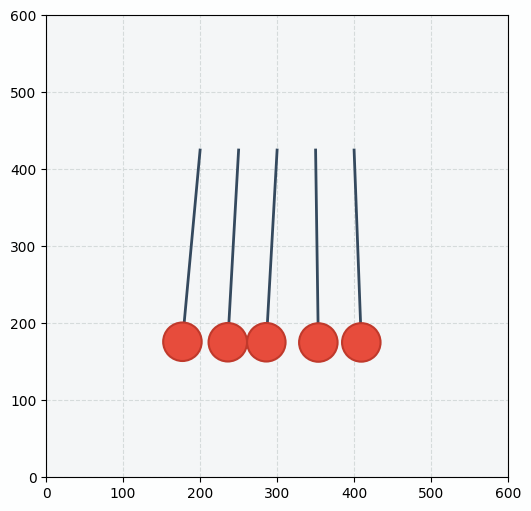

In [13]:
# @title 調整物理參數 { run: "auto" }
DAMPING = 0.98      # @param {type:"slider", min:0.9, max:1.0, step:0.001}
ELASTICITY = 0.95    # @param {type:"slider", min:0.5, max:1.0, step:0.01}

# 1. 建立新的物理空間並套用調整後的參數
def setup_custom_space(damping_val):
    space = pymunk.Space()
    space.gravity = 0, -9820
    space.damping = damping_val
    return space

def setup_custom_balls(space, elasticity_val):
    width = 600
    height = 600
    for x in range(-100, 150, 50):
        x += width / 2
        offset_y = height / 2
        mass = 10
        radius = 25
        moment = pymunk.moment_for_circle(mass, 0, radius, (0, 0))
        body = pymunk.Body(mass, moment)
        body.position = x, -125 + offset_y
        body.start_position = Vec2d(*body.position)
        shape = pymunk.Circle(body, radius)
        # 設定自訂的彈性係數
        shape.elasticity = elasticity_val
        space.add(body, shape)
        pj = pymunk.PinJoint(space.static_body, body, (x, 125 + offset_y), (0, 0))
        space.add(pj)

# 2. 建立畫布與圖表美化
fig, ax = plt.subplots(figsize=(6, 6))
fig.patch.set_facecolor('#fdfefe')
ax.set_facecolor('#f4f6f7')
ax.grid(True, linestyle='--', color='#d5dbdb', linewidth=0.8, zorder=1)
ax.set_xlim(0, 600)
ax.set_ylim(0, 600)
ax.set_aspect("equal")

# 初始化物理空間
custom_space = setup_custom_space(DAMPING)
setup_custom_balls(custom_space, ELASTICITY)

# 施加初始衝量
list(custom_space.shapes)[1].body.apply_impulse_at_local_point((-12000, 0))

custom_ball_artists = []
custom_line_artists = []

custom_balls = [shape for shape in custom_space.shapes if isinstance(shape, pymunk.Circle)]
custom_joints = [constraint for constraint in custom_space.constraints if isinstance(constraint, pymunk.PinJoint)]

for ball in custom_balls:
    # 改用珊瑚橘色 (Coral) 方便與先前版本區隔
    circle = patches.Circle((ball.body.position.x, ball.body.position.y),
                           radius=ball.radius, fc='#e74c3c', ec='#c0392b', lw=1.5, zorder=3)
    ax.add_patch(circle)
    custom_ball_artists.append(circle)

for joint in custom_joints:
    pos_a = joint.a.position + joint.anchor_a
    pos_b = joint.b.position + joint.anchor_b
    line, = ax.plot([pos_a.x, pos_b.x], [pos_a.y, pos_b.y], color='#34495e', lw=2, zorder=2)
    custom_line_artists.append(line)

def init_custom():
    return custom_ball_artists + custom_line_artists

def animate_custom(dt):
    for x in range(10):
        custom_space.step(1/50/10/2)

    for ball, circle in zip(custom_balls, custom_ball_artists):
        circle.set_center((ball.body.position.x, ball.body.position.y))

    for joint, line in zip(custom_joints, custom_line_artists):
        pos_a = joint.a.position + joint.anchor_a
        pos_b = joint.b.position + joint.anchor_b
        line.set_data([pos_a.x, pos_b.x], [pos_a.y, pos_b.y])

    return custom_ball_artists + custom_line_artists

# 增加總格數 (frames=150) 以便觀察長時間下的動能消散
anim_custom = animation.FuncAnimation(fig, animate_custom, init_func=init_custom,
                                      frames=150, interval=10, blit=True)

HTML(anim_custom.to_html5_video())